# DCNU-UNet++ : Multi-Task Retinal Vessel Segmentation + Classification + Thickness Regression

This notebook replaces the plain U-Net decoder of your **DCNU-Net multi-task** notebook with a **UNet++** (nested, densely-connected skip pathways + deep supervision), keeping your DCNU ingredients:

| Component | Where |
|---|---|
| Deformable convolution | backbone nodes `X0,0 ... X3,0` |
| SPP module | bottleneck node `X4,0` |
| LeakyReLU(0.01) | everywhere |
| Hybrid loss (Dice + 0.5·Focal) | applied to **every** deep-supervision head `X0,1 ... X0,4` |
| Classification + thickness regression heads | from pooled `X4,0` + clinical MLP (age, gender) |

**Mapping to your figure**

* Black circles `X^{i,0}` = backbone (encoder). Green circles `X^{i,j}`, `j>=1` = nested dense nodes: `X^{i,j} = H([X^{i,0}, ..., X^{i,j-1}, Up(X^{i+1,j-1})])`.
* `L` = deep-supervision loss on `X^{0,1}, X^{0,2}, X^{0,3}, X^{0,4}`.
* `UNet++ L1 ... L4` = **model pruning**: at inference you can stop at `X^{0,k}` and skip all deeper nodes. Section 10 evaluates L1-L4.

**Data split (CSV `group` column, patient-level):** group 1 = train, group 2 = validation, group 3 = test.

> **Lean mode:** `CFG["extras"] = False` -> the notebook only trains the multi-task model and reports test segmentation / classification / thickness-regression metrics. Set `extras = True` later to add bootstrap CIs, plots, qualitative figures and pruning/complexity tables for the Q1 package.

**Sections:** 1 Setup · 2 Config · 3 Data · 4 Dataset · 5 Model · 6 Loss/Metrics · 7 Training · 8 Curves · 9 Test evaluation · 10 Pruning L1-L4 · 11 Qualitative · 12 Inference helper · 13 Save summary

## 1. Setup

In [1]:
import os, re, glob, json, time, random, math, warnings
import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.ops import DeformConv2d

from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="ticks", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda | torch 2.11.0+cu128
GPU: Tesla T4


## 2. Config
Set the paths for your Kaggle dataset. Set `debug=True` for a 2-epoch smoke test on a tiny subset.

In [2]:
CFG = dict(
    images_dir = "/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset",
    masks_dir  = "/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806",
    csv_path   = "/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv",
    out_dir    = "/kaggle/working",
    img_size   = 512,
    batch_size = 8,
    epochs     = 30,
    lr         = 1e-4,
    weight_decay = 1e-5,
    num_workers = 2,
    base_ch    = 16,          # channels: 16-32-64-128-256
    deep_supervision = True,  # loss on X0,1..X0,4
    lam        = 0.5,         # Dice + lam * Focal
    w_seg = 1.0, w_cls = 1.0, w_reg = 1.0,
    amp        = True,        # mixed precision (GPU only)
    seed       = 42,
    extras     = False,   # True -> bootstrap CIs, ROC/Bland-Altman plots, qualitative figures, pruning / complexity (Q1 extras)
    debug      = False,
)
os.makedirs(CFG["out_dir"], exist_ok=True)
set_seed(CFG["seed"])
USE_AMP = bool(CFG["amp"] and device.type == "cuda")
if CFG["debug"]:
    CFG.update(epochs=2, img_size=128, batch_size=4)
CFG

{'images_dir': '/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset',
 'masks_dir': '/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806',
 'csv_path': '/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv',
 'out_dir': '/kaggle/working',
 'img_size': 512,
 'batch_size': 8,
 'epochs': 30,
 'lr': 0.0001,
 'weight_decay': 1e-05,
 'num_workers': 2,
 'base_ch': 16,
 'deep_supervision': True,
 'lam': 0.5,
 'w_seg': 1.0,
 'w_cls': 1.0,
 'w_reg': 1.0,
 'amp': True,
 'seed': 42,
 'extras': False,
 'debug': False}

## 3. Data
Split follows the CSV `group` column (**1 = train, 2 = validation, 3 = test**), with a patient-level leakage check (hard assert). Age and thickness are standardised **using training statistics only**; thickness metrics are reported back in original units.


In [3]:
def get_patient_id(base_name):
    return re.sub(r'(_L|_R|_OD|_OS)$', '', base_name, flags=re.IGNORECASE)

csv_df = pd.read_csv(CFG["csv_path"])
print(csv_df.shape); display(csv_df.head())

# CSV `group`:  1 = train,  2 = validation,  3 = test
train_df = csv_df[csv_df["group"] == 1].copy()
val_df   = csv_df[csv_df["group"] == 2].copy()
test_df  = csv_df[csv_df["group"] == 3].copy()
if CFG["debug"]:   # random (not head) subset so that both classes are present
    train_df = train_df.sample(32, random_state=0); val_df = val_df.sample(8, random_state=0); test_df = test_df.sample(8, random_state=0)
train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))   # row order == loader order

pid = lambda n: get_patient_id(os.path.splitext(str(n))[0])
tp_, vp_, sp_ = (set(d["image_name"].map(pid)) for d in (train_df, val_df, test_df))
print(f"patients train/val/test = {len(tp_)}/{len(vp_)}/{len(sp_)} | overlap tv={len(tp_&vp_)} tt={len(tp_&sp_)} vt={len(vp_&sp_)}")
assert not (tp_ & vp_) and not (tp_ & sp_) and not (vp_ & sp_), "Patient leakage between CSV groups!"
print("images train/val/test =", len(train_df), len(val_df), len(test_df))

SCALER = dict(age_mu=float(train_df["age"].mean()), age_sd=float(train_df["age"].std() + 1e-8),
              t_mu=float(train_df["thickness"].mean()), t_sd=float(train_df["thickness"].std() + 1e-8))
print(SCALER)
print("label counts (train):", train_df["label"].value_counts().to_dict())

(5806, 7)


,image_name,thickness,label,True_age,age,gender,group
0,2491006_R.png,0.8,0,63,0.684932,0,1
1,2491006_L.png,0.8,0,63,0.684932,0,1
2,3730004_R.png,1.2,1,61,0.657534,1,1
3,3730004_L.png,1.2,1,61,0.657534,1,1
4,3730006_R.png,1.2,1,64,0.698630,1,1


patients train/val/test = 2603/200/100 | overlap tv=0 tt=0 vt=0
images train/val/test = 5206 400 200
{'age_mu': 0.48080455110564735, 'age_sd': 0.17561490965730042, 't_mu': 0.9951325393776411, 't_sd': 0.18354104606772081}
label counts (train): {1: 3808, 0: 1398}


## 4. Dataset & DataLoaders

In [4]:
class MTDataset(Dataset):
    def __init__(self, images_dir, masks_dir, df, img_size=512, augment=False, scaler=SCALER):
        self.images_dir, self.masks_dir = images_dir, masks_dir
        self.df = df.reset_index(drop=True)
        self.img_size, self.augment, self.sc = img_size, augment, scaler

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        base = os.path.splitext(str(row["image_name"]))[0]
        s = self.img_size
        img  = Image.open(os.path.join(self.images_dir, base + ".png")).convert("RGB").resize((s, s), Image.BILINEAR)
        mask = Image.open(os.path.join(self.masks_dir,  base + "_mask.png")).convert("L").resize((s, s), Image.NEAREST)

        if self.augment:
            if random.random() < 0.5:
                img, mask = img.transpose(Image.FLIP_LEFT_RIGHT), mask.transpose(Image.FLIP_LEFT_RIGHT)
            if random.random() < 0.5:
                a = random.uniform(-15, 15)
                img, mask = img.rotate(a, resample=Image.BILINEAR), mask.rotate(a, resample=Image.NEAREST)

        img_np  = np.asarray(img, dtype=np.float32) / 255.0
        mask_np = (np.asarray(mask, dtype=np.float32) / 255.0 > 0.5).astype(np.float32)
        if self.augment and random.random() < 0.3:
            rng = np.random.default_rng()
            img_np = np.clip(img_np + rng.normal(0, 0.02, img_np.shape), 0, 1).astype(np.float32)

        age = (float(row["age"]) - self.sc["age_mu"]) / self.sc["age_sd"]
        clin = torch.tensor([age, float(row["gender"])], dtype=torch.float32)
        thick = (float(row["thickness"]) - self.sc["t_mu"]) / self.sc["t_sd"]
        return (torch.from_numpy(img_np).permute(2, 0, 1).contiguous(),
                torch.from_numpy(mask_np).unsqueeze(0),
                clin,
                torch.tensor(float(row["label"]), dtype=torch.float32),
                torch.tensor(thick, dtype=torch.float32))

def _seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def make_ds_loader(df, augment, shuffle):
    ds = MTDataset(CFG["images_dir"], CFG["masks_dir"], df, CFG["img_size"], augment)
    g = torch.Generator(); g.manual_seed(CFG["seed"])
    dl = DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, drop_last=augment,
                    num_workers=CFG["num_workers"], pin_memory=(device.type == "cuda"),
                    worker_init_fn=_seed_worker, generator=g)
    return ds, dl

train_ds, train_loader = make_ds_loader(train_df, True,  True)
val_ds,   val_loader   = make_ds_loader(val_df,   False, False)
test_ds,  test_loader  = make_ds_loader(test_df,  False, False)
print(f"train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}")

train=5206 val=400 test=200


## 5. Model — DCNU-UNet++ (multi-task)

Channels per depth: `[16, 32, 64, 128, 256]`.

* **Backbone** `X^{i,0}`: `i=0..3` = `ConvBlock -> DeformableConvBlock`; `i=4` = `ConvBlock -> SPP`.
* **Nested nodes** `X^{i,j}` (j ≥ 1): input channels `= c_i * j + c_{i+1}`, output `c_i`.
* **Deep supervision heads** on `X^{0,1..4}`; the final mask is the mean of heads (`fuse="mean"`) or only the last head (`fuse="last"`).
* **Pruning**: `forward(..., level=k)` computes only nodes with `i + j <= k` (UNet++ L^k).
* **Classification / regression** use pooled `X^{4,0}` + clinical MLP (only when `level=4`).

In [5]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout_p=0.0):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.LeakyReLU(0.01, inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.LeakyReLU(0.01, inplace=True))
        self.dropout = nn.Dropout2d(dropout_p) if dropout_p > 0 else nn.Identity()
    def forward(self, x): return self.dropout(self.block(x))


class DeformableConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, pad=1):
        super().__init__()
        self.offset_conv = nn.Conv2d(in_ch, 2 * k * k, k, padding=pad)
        nn.init.zeros_(self.offset_conv.weight); nn.init.zeros_(self.offset_conv.bias)
        self.deform = DeformConv2d(in_ch, out_ch, k, padding=pad)
        self.bn = nn.BatchNorm2d(out_ch); self.act = nn.LeakyReLU(0.01, inplace=True)
    def forward(self, x):
        return self.act(self.bn(self.deform(x, self.offset_conv(x))))


class EncoderStage(nn.Module):
    def __init__(self, in_ch, out_ch, dropout_p=0.0, deform=True):
        super().__init__()
        self.conv = ConvBlock(in_ch, out_ch, dropout_p)
        self.deform = DeformableConvBlock(out_ch, out_ch) if deform else nn.Identity()
    def forward(self, x): return self.deform(self.conv(x))


class SPPModule(nn.Module):
    def __init__(self, in_ch, branch_ch=16):
        super().__init__()
        self.b1 = nn.Conv2d(in_ch, branch_ch, 1)
        self.b3 = nn.Conv2d(in_ch, branch_ch, 3, padding=1)
        self.b5 = nn.Conv2d(in_ch, branch_ch, 5, padding=2)
        self.fuse = nn.Sequential(nn.Conv2d(branch_ch * 3 + in_ch, in_ch, 1),
                                  nn.BatchNorm2d(in_ch), nn.LeakyReLU(0.01, inplace=True))
    def forward(self, x):
        return self.fuse(torch.cat([x, self.b1(x), self.b3(x), self.b5(x)], 1))


class ClinicalMLP(nn.Module):
    def __init__(self, in_dim=2, hidden=32):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.LeakyReLU(0.01, inplace=True),
                                 nn.Linear(hidden, hidden), nn.LeakyReLU(0.01, inplace=True))
    def forward(self, x): return self.net(x)


class DCNUUNetPPMultiTask(nn.Module):
    def __init__(self, in_ch=3, base_ch=16, clinical_dim=2, clinical_hidden=32, fc_dim=128,
                 deep_supervision=True, use_deform=True, use_spp=True):
        super().__init__()
        self.deep_supervision = deep_supervision
        c = [base_ch * 2 ** i for i in range(5)]          # [16,32,64,128,256]
        self.c = c
        self.pool = nn.MaxPool2d(2)

        # ---- backbone X^{i,0} ----
        bb = [EncoderStage(in_ch, c[0], 0.1, use_deform), EncoderStage(c[0], c[1], 0.1, use_deform),
              EncoderStage(c[1], c[2], 0.2, use_deform), EncoderStage(c[2], c[3], 0.2, use_deform)]
        bb.append(nn.Sequential(ConvBlock(c[3], c[4], 0.3), SPPModule(c[4]) if use_spp else nn.Identity()))
        self.backbone = nn.ModuleList(bb)

        # ---- nested dense nodes X^{i,j}, j>=1 ----
        self.nodes = nn.ModuleDict()
        for j in range(1, 5):
            for i in range(0, 5 - j):
                self.nodes[f"{i}_{j}"] = ConvBlock(c[i] * j + c[i + 1], c[i], 0.1 if i < 2 else 0.2)

        # ---- deep supervision heads on X^{0,1..4} ----
        self.seg_heads = nn.ModuleList([
            nn.Sequential(nn.Conv2d(c[0], c[0], 1), nn.LeakyReLU(0.01, inplace=True), nn.Conv2d(c[0], 1, 1))
            for _ in range(4)])

        # ---- classification / regression ----
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.clinical_mlp = ClinicalMLP(clinical_dim, clinical_hidden)
        self.shared_fc = nn.Sequential(nn.Linear(c[4] + clinical_hidden, fc_dim), nn.LeakyReLU(0.01, inplace=True),
                                       nn.Dropout(0.3))
        self.cls_head = nn.Linear(fc_dim, 1)
        self.reg_head = nn.Linear(fc_dim, 1)

    def forward(self, x, clinical=None, level=4, fuse="mean"):
        X = {}
        X[(0, 0)] = self.backbone[0](x)
        for i in range(1, level + 1):
            X[(i, 0)] = self.backbone[i](self.pool(X[(i - 1, 0)]))

        for j in range(1, level + 1):
            for i in range(0, level - j + 1):
                up = F.interpolate(X[(i + 1, j - 1)], size=X[(i, 0)].shape[-2:], mode="bilinear", align_corners=False)
                inp = torch.cat([X[(i, k)] for k in range(j)] + [up], dim=1)
                X[(i, j)] = self.nodes[f"{i}_{j}"](inp)

        deep = [self.seg_heads[j - 1](X[(0, j)]) for j in range(1, level + 1)]
        if not self.deep_supervision:
            deep = deep[-1:]
        seg = deep[-1] if (fuse == "last" or len(deep) == 1) else torch.stack(deep, 0).mean(0)

        cls_logit = reg_pred = None
        if level == 4 and clinical is not None:
            fused = torch.cat([self.gap(X[(4, 0)]).flatten(1), self.clinical_mlp(clinical)], 1)
            h = self.shared_fc(fused)
            cls_logit, reg_pred = self.cls_head(h).squeeze(1), self.reg_head(h).squeeze(1)
        return dict(seg=seg, deep=deep, cls=cls_logit, reg=reg_pred)


def params_at_level(model, level):
    n = sum(p.numel() for i in range(level + 1) for p in model.backbone[i].parameters())
    n += sum(p.numel() for j in range(1, level + 1) for i in range(level - j + 1)
             for p in model.nodes[f"{i}_{j}"].parameters())
    n += sum(p.numel() for h in model.seg_heads[:level] for p in h.parameters())
    return n


model = DCNUUNetPPMultiTask(base_ch=CFG["base_ch"], deep_supervision=CFG["deep_supervision"]).to(device)
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print("Node channel table (in -> out):")
for k, m in model.nodes.items():
    print(f"  X{k.replace('_', ',')}: {m.block[0].in_channels:>4} -> {m.block[0].out_channels}")

with torch.no_grad():
    model.eval()
    o = model(torch.randn(2, 3, CFG["img_size"], CFG["img_size"], device=device), torch.randn(2, 2, device=device))
print("seg:", tuple(o["seg"].shape), "| deep heads:", len(o["deep"]), "| cls:", tuple(o["cls"].shape), "| reg:", tuple(o["reg"].shape))

Total parameters: 2,790,846
Node channel table (in -> out):
  X0,1:   48 -> 16
  X1,1:   96 -> 32
  X2,1:  192 -> 64
  X3,1:  384 -> 128
  X0,2:   64 -> 16
  X1,2:  128 -> 32
  X2,2:  256 -> 64
  X0,3:   80 -> 16
  X1,3:  160 -> 32
  X0,4:   96 -> 16
seg: (2, 1, 512, 512) | deep heads: 4 | cls: (2,) | reg: (2,)


## 6. Loss & Metrics
Hybrid loss `Dice + λ·Focal` averaged over all deep-supervision heads, plus weighted BCE (classification) and SmoothL1 (thickness).

In [6]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0): super().__init__(); self.smooth = smooth
    def forward(self, logits, t):
        p = torch.sigmoid(logits).flatten(1); t = t.flatten(1)
        inter = (p * t).sum(1)
        return 1 - ((2 * inter + self.smooth) / (p.sum(1) + t.sum(1) + self.smooth)).mean()

class FocalLoss(nn.Module):
    def __init__(self, alpha=0.8, gamma=2.0): super().__init__(); self.alpha, self.gamma = alpha, gamma
    def forward(self, logits, t):
        p = torch.sigmoid(logits).clamp(1e-6, 1 - 1e-6)
        pos = -self.alpha * (1 - p) ** self.gamma * t * torch.log(p)
        neg = -(1 - self.alpha) * p ** self.gamma * (1 - t) * torch.log(1 - p)
        return (pos + neg).mean()

n_pos, n_neg = int((train_df["label"] == 1).sum()), int((train_df["label"] == 0).sum())
pos_weight = torch.tensor(n_neg / max(n_pos, 1), dtype=torch.float32, device=device)
print(f"pos={n_pos} neg={n_neg} pos_weight={pos_weight.item():.3f}")

class MultiTaskLoss(nn.Module):
    def __init__(self, lam, w_seg, w_cls, w_reg, pos_weight):
        super().__init__()
        self.dice, self.focal, self.lam = DiceLoss(), FocalLoss(), lam
        self.bce, self.reg = nn.BCEWithLogitsLoss(pos_weight=pos_weight), nn.SmoothL1Loss()
        self.w = (w_seg, w_cls, w_reg)
    def forward(self, out, masks, labels, thick):
        seg = torch.stack([self.dice(h.float(), masks) + self.lam * self.focal(h.float(), masks)
                           for h in out["deep"]]).mean()       # deep supervision average
        cls = self.bce(out["cls"].float(), labels)
        reg = self.reg(out["reg"].float(), thick)
        return self.w[0] * seg + self.w[1] * cls + self.w[2] * reg, (seg.item(), cls.item(), reg.item())

criterion = MultiTaskLoss(CFG["lam"], CFG["w_seg"], CFG["w_cls"], CFG["w_reg"], pos_weight)


def per_image_seg(logits, masks, thr=0.5):
    p = (torch.sigmoid(logits.float()) > thr).float().flatten(1); t = masks.flatten(1)
    tp = (p * t).sum(1); fp = (p * (1 - t)).sum(1); fn = ((1 - p) * t).sum(1); tn = ((1 - p) * (1 - t)).sum(1)
    e = 1e-8
    d = dict(Dice=2 * tp / (2 * tp + fp + fn + e), IoU=tp / (tp + fp + fn + e),
             ACC=(tp + tn) / (tp + tn + fp + fn + e), SE=tp / (tp + fn + e), SP=tn / (tn + fp + e))
    return {k: v.cpu().numpy() for k, v in d.items()}


def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)


@torch.no_grad()
def evaluate(model, loader, criterion=None, level=4, fuse="mean", collect_pixels=False, pix_per_img=2000):
    model.eval()
    seg = {k: [] for k in ["Dice", "IoU", "ACC", "SE", "SP"]}
    cls_p, cls_t, reg_p, reg_t, pix_p, pix_t = [], [], [], [], [], []
    tot, n = 0.0, 0
    for imgs, masks, clin, labels, thick in loader:
        imgs, masks, clin = imgs.to(device), masks.to(device), clin.to(device)
        labels, thick = labels.to(device), thick.to(device)
        with autocast_ctx():
            out = model(imgs, clin, level=level, fuse=fuse)
        if criterion is not None and out["cls"] is not None:
            tot += criterion(out, masks, labels, thick)[0].item() * imgs.size(0)
        n += imgs.size(0)
        for k, v in per_image_seg(out["seg"], masks).items(): seg[k].append(v)
        if out["cls"] is not None:
            cls_p.append(torch.sigmoid(out["cls"].float()).cpu().numpy()); cls_t.append(labels.cpu().numpy())
            reg_p.append(out["reg"].float().cpu().numpy() * SCALER["t_sd"] + SCALER["t_mu"])
            reg_t.append(thick.cpu().numpy() * SCALER["t_sd"] + SCALER["t_mu"])
        if collect_pixels:
            pr = torch.sigmoid(out["seg"].float()).flatten(1); tg = masks.flatten(1)
            idx = torch.randint(0, pr.shape[1], (pix_per_img,), device=pr.device)
            pix_p.append(pr[:, idx].cpu().numpy().ravel()); pix_t.append(tg[:, idx].cpu().numpy().ravel())
    res = dict(seg={k: np.concatenate(v) for k, v in seg.items()}, loss=tot / max(n, 1))
    if cls_p:
        res.update(cls_prob=np.concatenate(cls_p), cls_true=np.concatenate(cls_t),
                   reg_pred=np.concatenate(reg_p), reg_true=np.concatenate(reg_t))
    if collect_pixels:
        res.update(pix_prob=np.concatenate(pix_p), pix_true=np.concatenate(pix_t))
    return res


def summarize(res):
    m = {f"seg_{k}": float(v.mean()) for k, v in res["seg"].items()}
    if "cls_prob" in res:
        y, p = res["cls_true"], res["cls_prob"]
        m["cls_ACC"] = accuracy_score(y, p > 0.5)
        m["cls_AUC"] = roc_auc_score(y, p) if len(np.unique(y)) > 1 else float("nan")
        m["reg_MAE"] = mean_absolute_error(res["reg_true"], res["reg_pred"])
        m["reg_RMSE"] = mean_squared_error(res["reg_true"], res["reg_pred"]) ** 0.5
        m["reg_R2"] = r2_score(res["reg_true"], res["reg_pred"])
    return m

pos=3808 neg=1398 pos_weight=0.367


## 7. Training
Adam + `ReduceLROnPlateau`, optional AMP, gradient clipping. Best checkpoint = highest `seg_Dice + cls_ACC + reg_R2` on the validation set.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
try:
    grad_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
except Exception:
    grad_scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

def train_one_epoch(model, loader):
    model.train(); tot = seg_t = cls_t = reg_t = 0.0
    for imgs, masks, clin, labels, thick in loader:
        imgs, masks, clin = imgs.to(device), masks.to(device), clin.to(device)
        labels, thick = labels.to(device), thick.to(device)
        optimizer.zero_grad(set_to_none=True)
        with autocast_ctx():
            out = model(imgs, clin)
        loss, (s, c, r) = criterion(out, masks, labels, thick)
        grad_scaler.scale(loss).backward()
        grad_scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        grad_scaler.step(optimizer); grad_scaler.update()
        b = imgs.size(0); tot += loss.item() * b; seg_t += s * b; cls_t += c * b; reg_t += r * b
    n = len(loader.dataset) if not loader.drop_last else len(loader) * loader.batch_size
    return tot / n, seg_t / n, cls_t / n, reg_t / n

best_score, history = -1e9, []
best_ckpt = os.path.join(CFG["out_dir"], "dcnu_unetpp_multitask_best.pth")

for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    tr_loss, tr_seg, tr_cls, tr_reg = train_one_epoch(model, train_loader)
    vres = evaluate(model, val_loader, criterion)
    vm = summarize(vres)
    scheduler.step(vres["loss"])
    score = vm["seg_Dice"] + vm["cls_ACC"] + vm["reg_R2"]
    history.append(dict(epoch=epoch, train_loss=tr_loss, train_seg=tr_seg, train_cls=tr_cls, train_reg=tr_reg,
                        val_loss=vres["loss"], lr=optimizer.param_groups[0]["lr"], **vm))
    flag = ""
    if score > best_score:
        best_score = score; torch.save(model.state_dict(), best_ckpt); flag = "  <- best"
    print(f"Ep {epoch:03d}/{CFG['epochs']} ({time.time()-t0:.0f}s) loss {tr_loss:.3f}/{vres['loss']:.3f} | "
          f"Dice {vm['seg_Dice']:.4f} IoU {vm['seg_IoU']:.4f} | cls ACC {vm['cls_ACC']:.3f} AUC {vm['cls_AUC']:.3f} | "
          f"MAE {vm['reg_MAE']:.4f} R2 {vm['reg_R2']:.3f}{flag}")

hist_df = pd.DataFrame(history)
hist_df.to_csv(os.path.join(CFG["out_dir"], "unetpp_training_history.csv"), index=False)
torch.save(model.state_dict(), os.path.join(CFG["out_dir"], "dcnu_unetpp_multitask_last.pth"))

Ep 001/30 (713s) loss 1.443/1.514 | Dice 0.7381 IoU 0.5884 | cls ACC 0.713 AUC 0.829 | MAE 0.1563 R2 0.220  <- best
Ep 002/30 (721s) loss 0.992/1.018 | Dice 0.8476 IoU 0.7369 | cls ACC 0.775 AUC 0.864 | MAE 0.1382 R2 0.346  <- best
Ep 003/30 (720s) loss 0.788/0.906 | Dice 0.8816 IoU 0.7892 | cls ACC 0.775 AUC 0.866 | MAE 0.1346 R2 0.374  <- best
Ep 004/30 (723s) loss 0.738/0.886 | Dice 0.8956 IoU 0.8117 | cls ACC 0.775 AUC 0.869 | MAE 0.1360 R2 0.366  <- best
Ep 005/30 (723s) loss 0.717/0.887 | Dice 0.9034 IoU 0.8243 | cls ACC 0.780 AUC 0.865 | MAE 0.1355 R2 0.362  <- best
Ep 006/30 (724s) loss 0.705/0.915 | Dice 0.9096 IoU 0.8347 | cls ACC 0.765 AUC 0.865 | MAE 0.1370 R2 0.352
Ep 007/30 (725s) loss 0.702/0.869 | Dice 0.9106 IoU 0.8364 | cls ACC 0.782 AUC 0.866 | MAE 0.1372 R2 0.370  <- best
Ep 008/30 (724s) loss 0.698/0.862 | Dice 0.9118 IoU 0.8383 | cls ACC 0.785 AUC 0.868 | MAE 0.1362 R2 0.367  <- best
Ep 009/30 (724s) loss 0.693/0.856 | Dice 0.9168 IoU 0.8468 | cls ACC 0.787 AUC 0.

## 8. Training Curves

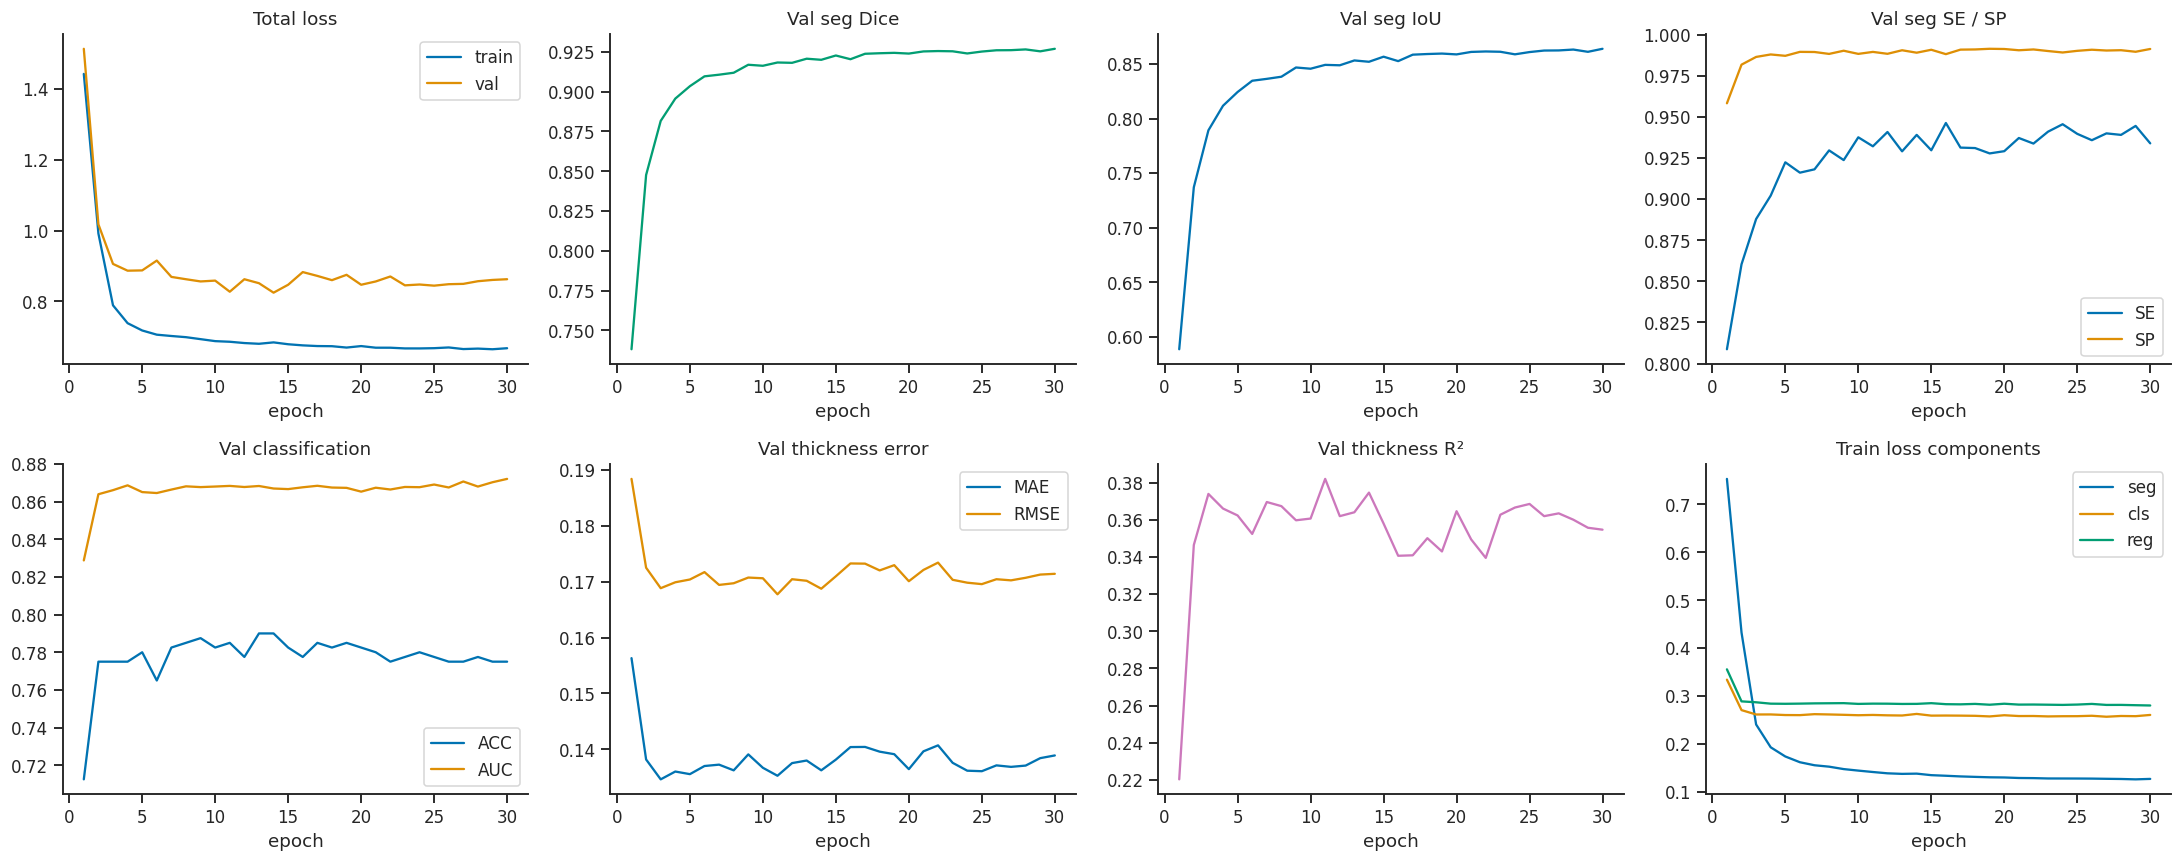

In [8]:
fig, ax = plt.subplots(2, 4, figsize=(20, 8))
ax[0,0].plot(hist_df.epoch, hist_df.train_loss, label="train"); ax[0,0].plot(hist_df.epoch, hist_df.val_loss, label="val"); ax[0,0].set_title("Total loss"); ax[0,0].legend()
ax[0,1].plot(hist_df.epoch, hist_df.seg_Dice, color="C2"); ax[0,1].set_title("Val seg Dice")
ax[0,2].plot(hist_df.epoch, hist_df.seg_IoU, color="C0"); ax[0,2].set_title("Val seg IoU")
ax[0,3].plot(hist_df.epoch, hist_df.seg_SE, label="SE"); ax[0,3].plot(hist_df.epoch, hist_df.seg_SP, label="SP"); ax[0,3].set_title("Val seg SE / SP"); ax[0,3].legend()
ax[1,0].plot(hist_df.epoch, hist_df.cls_ACC, label="ACC"); ax[1,0].plot(hist_df.epoch, hist_df.cls_AUC, label="AUC"); ax[1,0].set_title("Val classification"); ax[1,0].legend()
ax[1,1].plot(hist_df.epoch, hist_df.reg_MAE, label="MAE"); ax[1,1].plot(hist_df.epoch, hist_df.reg_RMSE, label="RMSE"); ax[1,1].set_title("Val thickness error"); ax[1,1].legend()
ax[1,2].plot(hist_df.epoch, hist_df.reg_R2, color="C4"); ax[1,2].set_title("Val thickness R²")
ax[1,3].plot(hist_df.epoch, hist_df.train_seg, label="seg"); ax[1,3].plot(hist_df.epoch, hist_df.train_cls, label="cls"); ax[1,3].plot(hist_df.epoch, hist_df.train_reg, label="reg"); ax[1,3].set_title("Train loss components"); ax[1,3].legend()
for a in ax.flat: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "unetpp_training_curves.png")); plt.show()

## 9. Final Test Evaluation (best checkpoint, CSV group 3)
Core test metrics for segmentation, classification and thickness regression. Patient-level bootstrap CIs and the ROC / Bland-Altman figures run only when `CFG["extras"] = True`.


In [9]:
model.load_state_dict(torch.load(best_ckpt, map_location=device))
res = evaluate(model, test_loader, criterion, collect_pixels=True)
tm = summarize(res)
tm["seg_AUC_pixel"] = roc_auc_score(res["pix_true"], res["pix_prob"])
y, p = res["cls_true"], res["cls_prob"]
tt, tp_pred = res["reg_true"], res["reg_pred"]
tm["cls_F1"] = f1_score(y, p > .5)
tm["cls_Precision"] = precision_score(y, p > .5, zero_division=0)
tm["cls_Recall"] = recall_score(y, p > .5)

test_table = pd.DataFrame({"metric": list(tm.keys()), "value": list(tm.values())}).round(4)
test_table.to_csv(os.path.join(CFG["out_dir"], "unetpp_test_metrics.csv"), index=False)
display(test_table)
print(classification_report(y, (p > .5).astype(int), target_names=["class 0", "class 1"]))
print("confusion matrix [[TN, FP], [FN, TP]]:", confusion_matrix(y, (p > .5).astype(int)).tolist())

if CFG["extras"]:
    # ---- patient-level (cluster) bootstrap: resample patients, keep both eyes together ----
    test_pids = test_df["image_name"].map(pid).values            # same order as test_loader (shuffle=False)
    _pg = {}
    for _i, _p in enumerate(test_pids): _pg.setdefault(_p, []).append(_i)
    _pidx = [np.array(v) for v in _pg.values()]

    def boot_ci(fn, *arrs, strat=None, n_boot=1000, seed=42):
        """fn(*arrs) on every bootstrap resample of patients; `strat` (labels) -> skip resamples with one class only."""
        rng = np.random.default_rng(seed); vals = []
        for _ in range(n_boot):
            ix = np.concatenate([_pidx[k] for k in rng.integers(0, len(_pidx), len(_pidx))])
            if strat is not None and len(np.unique(strat[ix])) < 2: continue
            vals.append(fn(*[a[ix] for a in arrs]))
        return fn(*arrs), np.percentile(vals, 2.5), np.percentile(vals, 97.5)

    rows = []
    for k, v in res["seg"].items():
        m, lo, hi = boot_ci(lambda a: a.mean(), v); rows.append(("Segmentation", k, m, lo, hi))
    y, p = res["cls_true"], res["cls_prob"]
    for name, fn in [("ACC", lambda a, b: accuracy_score(a, b > .5)), ("AUC", roc_auc_score),
                     ("F1", lambda a, b: f1_score(a, b > .5)),
                     ("Precision", lambda a, b: precision_score(a, b > .5, zero_division=0)),
                     ("Recall/SE", lambda a, b: recall_score(a, b > .5))]:
        m, lo, hi = boot_ci(fn, y, p, strat=y); rows.append(("Classification", name, m, lo, hi))
    tt, tp_pred = res["reg_true"], res["reg_pred"]
    for name, fn in [("MAE", lambda a, b: mean_absolute_error(a, b)), ("RMSE", lambda a, b: mean_squared_error(a, b) ** .5),
                     ("R2", lambda a, b: r2_score(a, b))]:
        m, lo, hi = boot_ci(fn, tt, tp_pred); rows.append(("Thickness", name, m, lo, hi))

    test_table = pd.DataFrame(rows, columns=["Task", "Metric", "Mean", "CI low", "CI high"]).round(4)
    test_table.to_csv(os.path.join(CFG["out_dir"], "unetpp_test_metrics_ci.csv"), index=False)
    display(test_table)
    print(f"Pixel-level seg AUC (subsampled): {tm['seg_AUC_pixel']:.4f}")
    print(classification_report(y, (p > 0.5).astype(int), target_names=["class 0", "class 1"]))

    fig, ax = plt.subplots(1, 4, figsize=(22, 4.8))
    sns.heatmap(confusion_matrix(y, (p > .5).astype(int)), annot=True, fmt="d", cmap="Blues", ax=ax[0],
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"]); ax[0].set_title("Confusion matrix (test)")
    fpr, tpr, _ = roc_curve(y, p); ax[1].plot(fpr, tpr, label=f"AUC={tm['cls_AUC']:.3f}"); ax[1].plot([0,1],[0,1],"--",c="gray")
    ax[1].set_title("ROC (test)"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend()
    ax[2].scatter(tt, tp_pred, s=14, alpha=.4); lim = [min(tt.min(), tp_pred.min()), max(tt.max(), tp_pred.max())]
    ax[2].plot(lim, lim, "--", c="gray"); ax[2].set_title(f"Thickness (MAE={tm['reg_MAE']:.3f}, R²={tm['reg_R2']:.3f})")
    ax[2].set_xlabel("true"); ax[2].set_ylabel("predicted")
    mean_ = (tt + tp_pred) / 2; diff = tp_pred - tt; bias, sd = diff.mean(), diff.std()
    ax[3].scatter(mean_, diff, s=14, alpha=.4); ax[3].axhline(bias, c="r"); ax[3].axhline(bias + 1.96*sd, ls="--", c="gray"); ax[3].axhline(bias - 1.96*sd, ls="--", c="gray")
    ax[3].set_title("Bland-Altman (thickness)"); ax[3].set_xlabel("mean"); ax[3].set_ylabel("pred - true")
    plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "unetpp_test_results.png")); plt.show()

,metric,value
0,seg_Dice,0.9180
1,seg_IoU,0.8488
2,seg_ACC,0.9840
3,seg_SE,0.9308
4,seg_SP,0.9894
5,cls_ACC,0.8400
6,cls_AUC,0.9469
7,reg_MAE,0.1071
8,reg_RMSE,0.1377
9,reg_R2,0.4849


              precision    recall  f1-score   support

     class 0       0.90      0.76      0.83       100
     class 1       0.79      0.92      0.85       100

    accuracy                           0.84       200
   macro avg       0.85      0.84      0.84       200
weighted avg       0.85      0.84      0.84       200

confusion matrix [[TN, FP], [FN, TP]]: [[76, 24], [8, 92]]


## 10. UNet++ Pruning L1–L4 (right side of your figure)
Because of deep supervision, the trained network can be truncated at `X0,k` at inference. Only segmentation is available for pruned levels (the classification/regression heads need `X4,0`).

*(runs only when `CFG["extras"] = True`)*


In [10]:
if CFG["extras"]:
    def latency_ms(level, n_runs=10, n_warm=3):
        x = torch.randn(1, 3, CFG["img_size"], CFG["img_size"], device=device); model.eval()
        with torch.no_grad():
            for _ in range(n_warm):
                with autocast_ctx(): model(x, level=level)
            if device.type == "cuda": torch.cuda.synchronize()
            t0 = time.time()
            for _ in range(n_runs):
                with autocast_ctx(): model(x, level=level)
            if device.type == "cuda": torch.cuda.synchronize()
        return (time.time() - t0) / n_runs * 1000

    prune_rows = []
    for level in [1, 2, 3, 4]:
        for fuse in (["last"] if level == 1 else ["last", "mean"]):
            r = evaluate(model, test_loader, level=level, fuse=fuse)
            prune_rows.append(dict(Model=f"UNet++ L{level} ({'X0,%d only' % level if fuse == 'last' else 'mean of heads'})",
                                   Level=level, Fuse=fuse, Params_M=params_at_level(model, level) / 1e6,
                                   Latency_ms=latency_ms(level), **{k: v.mean() for k, v in r["seg"].items()}))
    prune_df = pd.DataFrame(prune_rows).round(4)
    prune_df.to_csv(os.path.join(CFG["out_dir"], "unetpp_pruning_L1_L4.csv"), index=False)
    display(prune_df)

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    d = prune_df[prune_df.Fuse == "last"]
    ax[0].plot(d.Level, d.Dice, "o-"); ax[0].set_xticks([1, 2, 3, 4]); ax[0].set_xlabel("pruning level L"); ax[0].set_ylabel("Test Dice"); ax[0].set_title("Dice vs. pruning level")
    ax[1].plot(d.Params_M, d.Dice, "o-")
    for _, r in d.iterrows(): ax[1].annotate(f"L{int(r.Level)}", (r.Params_M, r.Dice), textcoords="offset points", xytext=(5, 5))
    ax[1].set_xlabel("parameters (M)"); ax[1].set_ylabel("Test Dice"); ax[1].set_title("Accuracy / size trade-off")
    plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "unetpp_pruning.png")); plt.show()

## 11. Qualitative Results — every deep-supervision head
Best / median / worst / random test image. Error map: white = TP, red = FP, blue = FN.

*(runs only when `CFG["extras"] = True`)*


In [11]:
if CFG["extras"]:
    dice = res["seg"]["Dice"]; order = np.argsort(dice)
    rng = np.random.default_rng(0)
    picks = [("best", order[-1]), ("median", order[len(order) // 2]), ("worst", order[0]), ("random", int(rng.integers(len(order))))]
    ncol = 8
    fig, ax = plt.subplots(len(picks), ncol, figsize=(3 * ncol, 3 * len(picks)))
    model.eval()
    for r_i, (tag, idx) in enumerate(picks):
        img, mask, clin, lab, th = test_ds[int(idx)]
        with torch.no_grad(), autocast_ctx():
            out = model(img[None].to(device), clin[None].to(device))
        gt = mask[0].numpy() > 0.5
        final = torch.sigmoid(out["seg"].float())[0, 0].cpu().numpy()
        pred = final > 0.5
        err = np.zeros(gt.shape + (3,)); err[gt & pred] = 1; err[~gt & pred] = [1, 0, 0]; err[gt & ~pred] = [0, .4, 1]
        ax[r_i, 0].imshow(img.permute(1, 2, 0).numpy()); ax[r_i, 0].set_title(f"{tag} (Dice={dice[idx]:.3f})")
        ax[r_i, 1].imshow(gt, cmap="gray"); ax[r_i, 1].set_title("ground truth")
        for j, h in enumerate(out["deep"]):
            ax[r_i, 2 + j].imshow(torch.sigmoid(h.float())[0, 0].cpu().numpy(), cmap="magma", vmin=0, vmax=1); ax[r_i, 2 + j].set_title(f"X0,{j+1} head")
        ax[r_i, 6].imshow(final, cmap="magma", vmin=0, vmax=1); ax[r_i, 6].set_title("final (mean heads)")
        ax[r_i, 7].imshow(err); ax[r_i, 7].set_title("error map")
    for a in ax.flat: a.axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "unetpp_qualitative.png")); plt.show()

## 12. Inference Helper (single image)

In [12]:
@torch.no_grad()
def predict_single(image_path, age, gender, thr=0.5):
    model.eval(); s = CFG["img_size"]
    img = Image.open(image_path).convert("RGB").resize((s, s), Image.BILINEAR)
    x = torch.from_numpy(np.asarray(img, dtype=np.float32) / 255.).permute(2, 0, 1)[None].to(device)
    clin = torch.tensor([[(age - SCALER["age_mu"]) / SCALER["age_sd"], float(gender)]], dtype=torch.float32, device=device)
    out = model(x, clin)
    return dict(vessel_prob=torch.sigmoid(out["seg"])[0, 0].cpu().numpy(),
                class_prob=torch.sigmoid(out["cls"]).item(),
                thickness=out["reg"].item() * SCALER["t_sd"] + SCALER["t_mu"])

# example:
# r = predict_single(os.path.join(CFG["images_dir"], test_df.iloc[0]["image_name"]), age=55, gender=1)
# print(r["class_prob"], r["thickness"])

## 13. Save Summary

In [13]:
summary = pd.DataFrame([{**tm, "params_M": sum(p.numel() for p in model.parameters()) / 1e6}],
                       index=["DCNU-UNet++ Multi-Task (test, CSV group 3)"])
summary.to_csv(os.path.join(CFG["out_dir"], "unetpp_results_summary.csv"))
with open(os.path.join(CFG["out_dir"], "unetpp_config.json"), "w") as f:
    json.dump(dict(CFG=CFG, SCALER=SCALER), f, indent=2)
display(summary.T)
print("Saved to:", CFG["out_dir"])

,"DCNU-UNet++ Multi-Task (test, CSV group 3)"
seg_Dice,0.917981
seg_IoU,0.848770
seg_ACC,0.983973
seg_SE,0.930811
seg_SP,0.989432
cls_ACC,0.840000
cls_AUC,0.946900
reg_MAE,0.107066
reg_RMSE,0.137685
reg_R2,0.484913


Saved to: /kaggle/working
